# Problema de Clasificación con Scikit-learn

In [1]:
# Librerías Básicas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Procesamiento
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Modelos
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier

# Métricas
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, ConfusionMatrixDisplay
)

In [3]:
# 2. Cargar datos
df = pd.read_csv("/content/Titanic-Dataset.csv")
# df = pd.read_excel("datos.xlsx")  # Usar esta línea para Excel

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
df = df.dropna()

In [9]:
dataset = df[["Pclass", "Sex", "Age", "Fare", "Survived"]]

In [10]:
dataset

,Pclass,Sex,Age,Fare,Survived
1,1,female,38.0,71.2833,1
3,1,female,35.0,53.1000,1
6,1,male,54.0,51.8625,0
10,3,female,4.0,16.7000,1
11,1,female,58.0,26.5500,1
...,...,...,...,...,...
871,1,female,47.0,52.5542,1
872,1,male,33.0,5.0000,0
879,1,female,56.0,83.1583,1
887,1,female,19.0,30.0000,1


In [11]:
dataset["Sex"] = dataset["Sex"].map({"female":0, "male":1})

/tmp/ipykernel_2515/2646032285.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dataset["Sex"] = dataset["Sex"].map({"female":0, "male":1})


In [12]:
dataset

,Pclass,Sex,Age,Fare,Survived
1,1,0,38.0,71.2833,1
3,1,0,35.0,53.1000,1
6,1,1,54.0,51.8625,0
10,3,0,4.0,16.7000,1
11,1,0,58.0,26.5500,1
...,...,...,...,...,...
871,1,0,47.0,52.5542,1
872,1,1,33.0,5.0000,0
879,1,0,56.0,83.1583,1
887,1,0,19.0,30.0000,1


In [13]:
# Cambiar "objetivo" por el nombre de la columna que deseas predecir
X = dataset[["Pclass", "Sex", "Age", "Fare"]].values
y = dataset["Survived"].values

In [17]:
# 4. Dividir y escalar
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
# Escalar
#scaler = StandardScaler()
#X_train = scaler.fit_transform(X_train)
#X_test = scaler.transform(X_test)

In [31]:
# 5. Crear y entrenar el modelo

# class_weight="balanced" ayuda cuando una clase tiene menos datos
#modelo = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
#modelo.fit(X_train, y_train)

modelo = DecisionTreeClassifier(max_depth=3, random_state=42)
modelo.fit(X_train, y_train)

modelo1 = RandomForestClassifier(n_estimators=100, max_depth=3, random_state=42)
modelo1.fit(X_train, y_train)

modelo2 = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
modelo2.fit(X_train, y_train)

GradientBoostingClassifier(random_state=42)

Accuracy: 0.7837837837837838
Precision: 0.9473684210526315
Recall: 0.72
F1: 0.8181818181818182
AUC: 0.835


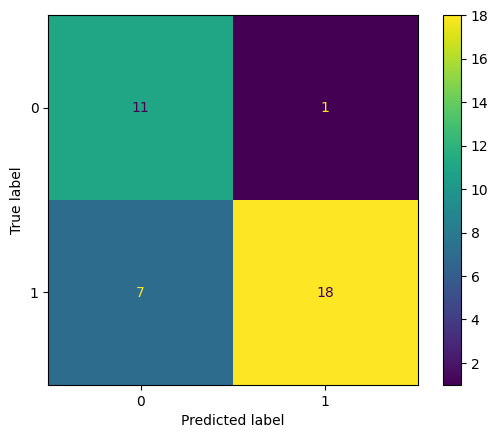

In [25]:
# 6. Evaluar el modelo
y_pred = modelo.predict(X_test)
y_prob = modelo.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1:", f1_score(y_test, y_pred, zero_division=0))
print("AUC:", roc_auc_score(y_test, y_prob))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.show()

<BarContainer object of 4 artists>

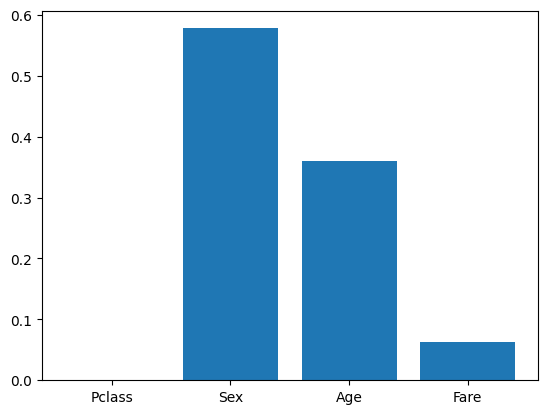

In [30]:
categorias = ["Pclass","Sex", "Age", "Fare"]
plt.bar(categorias, modelo.feature_importances_)

Accuracy: 0.8108108108108109
Precision: 0.8461538461538461
Recall: 0.88
F1: 0.8627450980392157
AUC: 0.87


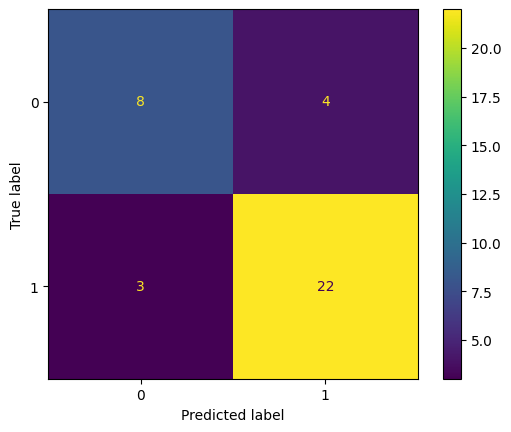

In [27]:
# 6. Evaluar el modelo1
y_pred = modelo1.predict(X_test)
y_prob = modelo1.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1:", f1_score(y_test, y_pred, zero_division=0))
print("AUC:", roc_auc_score(y_test, y_prob))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.show()

<BarContainer object of 4 artists>

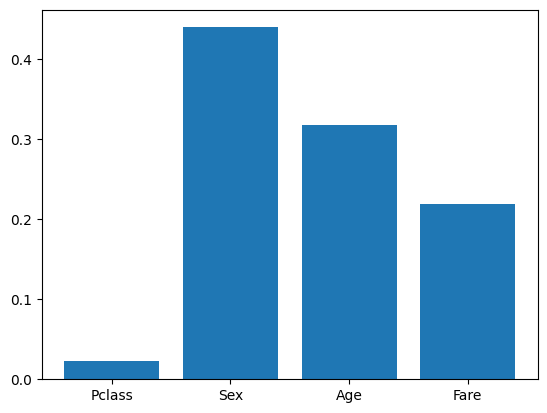

In [29]:
categorias = ["Pclass","Sex", "Age", "Fare"]
plt.bar(categorias, modelo1.feature_importances_)

Accuracy: 0.8378378378378378
Precision: 0.88
Recall: 0.88
F1: 0.88
AUC: 0.92


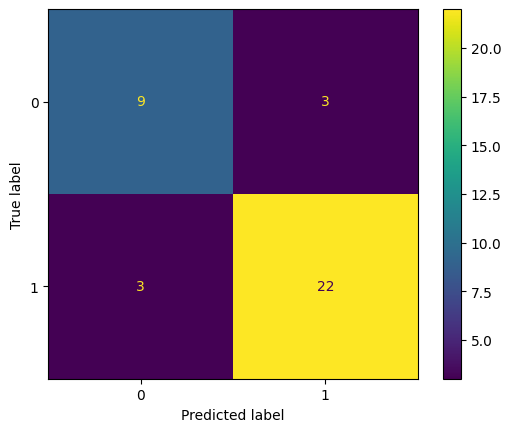

In [34]:
# 6. Evaluar el modelo2
y_pred = modelo2.predict(X_test)
y_prob = modelo2.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1:", f1_score(y_test, y_pred, zero_division=0))
print("AUC:", roc_auc_score(y_test, y_prob))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.show()

<BarContainer object of 4 artists>

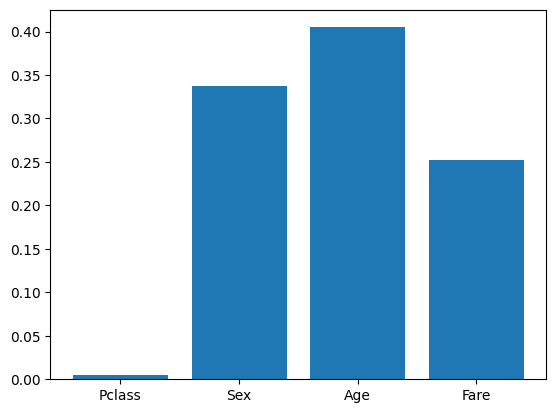

In [33]:
categorias = ["Pclass","Sex", "Age", "Fare"]
plt.bar(categorias, modelo2.feature_importances_)